## Step 1 — Imports


In [1]:
# Data handling and visualization
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset
from datasets import load_dataset

# Feature extraction
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import FeatureUnion, Pipeline

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# File and reproducibility helpers
from pathlib import Path

RANDOM_STATE = 42


## Step 2 — Load Banking77


In [2]:
dataset = load_dataset("mteb/banking77")

train_df = dataset["train"].to_pandas()
test_df = dataset["test"].to_pandas()

print("Training rows:", len(train_df))
print("Test rows:", len(test_df))
print("Number of intents:", train_df["label_text"].nunique())
display(train_df.head())


Training rows: 9993
Test rows: 3076
Number of intents: 77


,text,label,label_text
0,I am still waiting on my card?,11,card_arrival
1,What can I do if my card still hasn't arrived ...,11,card_arrival
2,I have been waiting over a week. Is the card s...,11,card_arrival
3,Can I track my card while it is in the process...,11,card_arrival
4,"How do I know if I will get my card, or if it ...",11,card_arrival


## Step 3 — Explore and validate the data


In [3]:
print("Training data information:")
train_df.info()

print("\nMissing values:")
display(train_df.isnull().sum())

print("Duplicate rows:", train_df.duplicated().sum())
print("Duplicate texts:", train_df["text"].duplicated().sum())

print(
    "Texts assigned to multiple intents:",
    (train_df.groupby("text")["label_text"].nunique() > 1).sum()
)


Training data information:
<class 'pandas.DataFrame'>
RangeIndex: 9993 entries, 0 to 9992
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   text        9993 non-null   str  
 1   label       9993 non-null   int64
 2   label_text  9993 non-null   str  
dtypes: int64(1), str(2)
memory usage: 1021.3 KB

Missing values:


text          0
label         0
label_text    0
dtype: int64

Duplicate rows: 0
Duplicate texts: 0
Texts assigned to multiple intents: 0


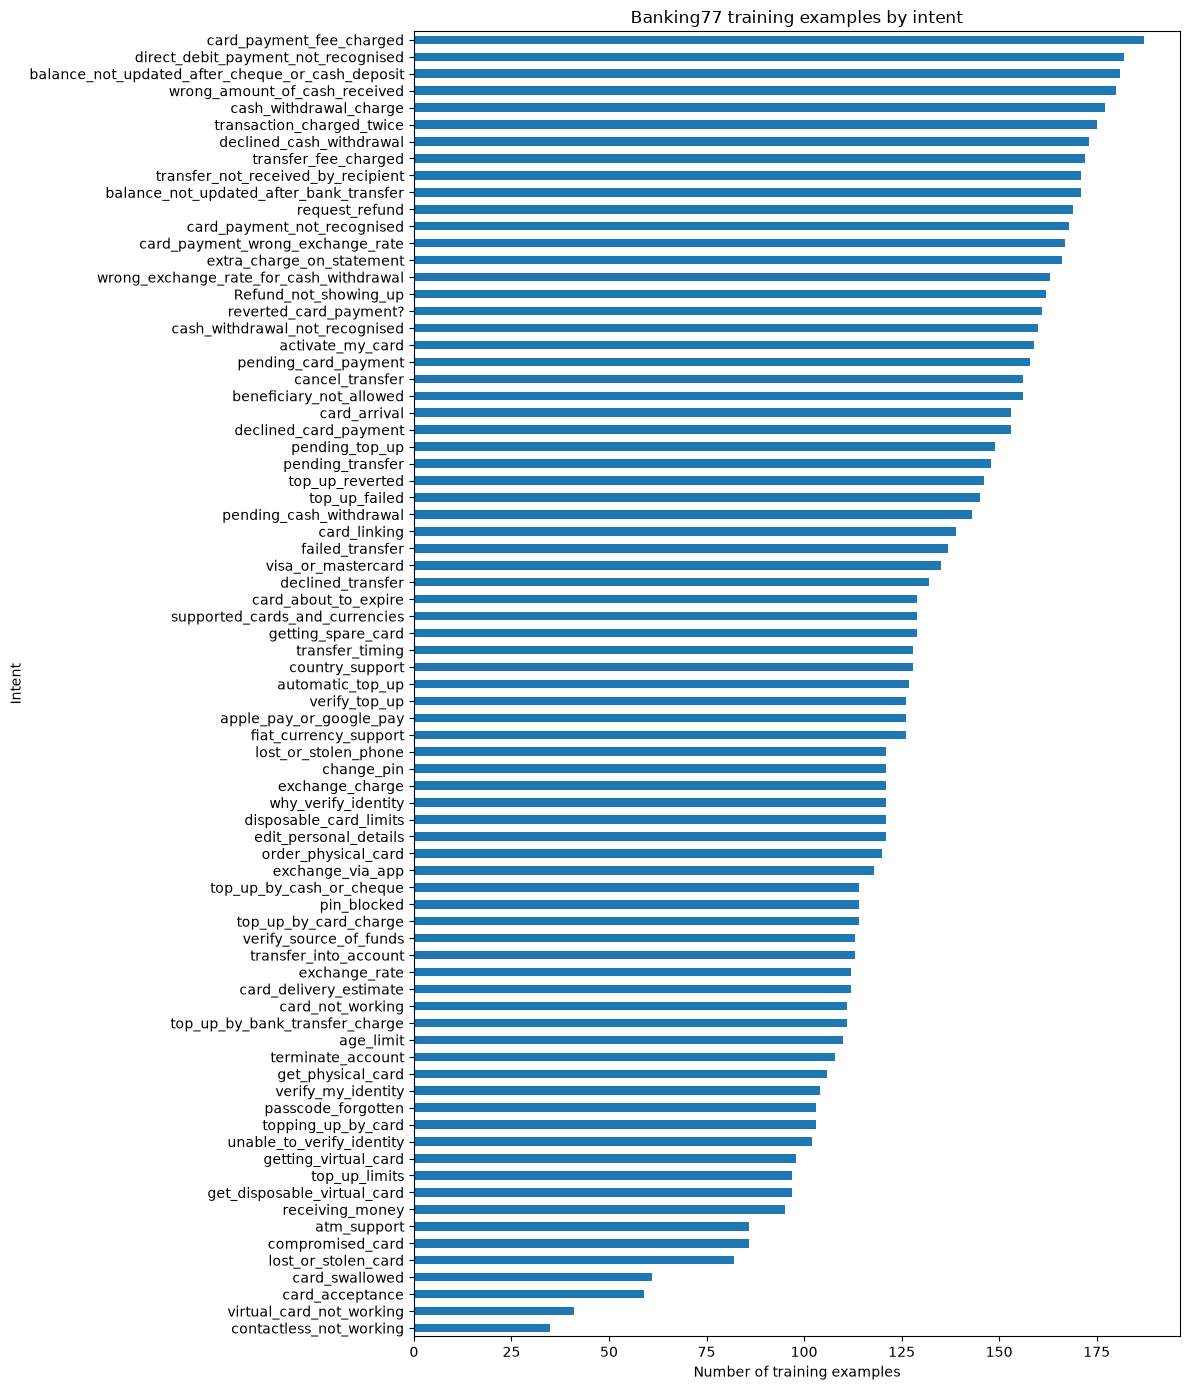

,char_count,word_count
count,9993.000000,9993.000000
mean,59.501351,11.955369
std,40.873384,7.891187
min,13.000000,3.000000
25%,36.000000,7.000000
50%,47.000000,10.000000
75%,64.000000,13.000000
max,433.000000,79.000000


In [4]:
intent_counts = train_df["label_text"].value_counts().sort_values()

plt.figure(figsize=(12, 14))
intent_counts.plot(kind="barh")
plt.xlabel("Number of training examples")
plt.ylabel("Intent")
plt.title("Banking77 training examples by intent")
plt.tight_layout()
plt.show()

train_df["char_count"] = train_df["text"].str.len()
train_df["word_count"] = train_df["text"].str.split().str.len()

display(train_df[["char_count", "word_count"]].describe())


## Step 4 — Prepare features, labels, and the intent mapping


In [5]:
X_train = train_df["text"].astype(str)
y_train = train_df["label"]

X_test = test_df["text"].astype(str)
y_test = test_df["label"]

label_mapping = (
    train_df[["label", "label_text"]]
    .drop_duplicates()
    .sort_values("label")
    .reset_index(drop=True)
)

labels = label_mapping["label"].tolist()
target_names = label_mapping["label_text"].tolist()

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("Number of intents:", len(label_mapping))
display(label_mapping.head())


X_train: (9993,)
X_test: (3076,)
Number of intents: 77


,label,label_text
0,0,activate_my_card
1,1,age_limit
2,2,apple_pay_or_google_pay
3,3,atm_support
4,4,automatic_top_up


## Step 5 — Establish baseline models


In [6]:
# Bag of Words features
bow_vectorizer = CountVectorizer()
X_train_bow = bow_vectorizer.fit_transform(X_train)
X_test_bow = bow_vectorizer.transform(X_test)

# Word TF-IDF features
tfidf_vectorizer = TfidfVectorizer()
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

print("BoW feature count:", X_train_bow.shape[1])
print("Word TF-IDF feature count:", X_train_tfidf.shape[1])


BoW feature count: 2319
Word TF-IDF feature count: 2319


In [7]:
baseline_results = []

# BoW + Logistic Regression
bow_lr = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
bow_lr.fit(X_train_bow, y_train)
pred_bow_lr = bow_lr.predict(X_test_bow)
baseline_results.append({
    "Model": "BoW + Logistic Regression",
    "Accuracy": accuracy_score(y_test, pred_bow_lr),
    "Macro F1": f1_score(y_test, pred_bow_lr, average="macro")
})

# TF-IDF + Logistic Regression
tfidf_lr = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
tfidf_lr.fit(X_train_tfidf, y_train)
pred_tfidf_lr = tfidf_lr.predict(X_test_tfidf)
baseline_results.append({
    "Model": "TF-IDF + Logistic Regression",
    "Accuracy": accuracy_score(y_test, pred_tfidf_lr),
    "Macro F1": f1_score(y_test, pred_tfidf_lr, average="macro")
})

# BoW + Multinomial Naive Bayes
bow_nb = MultinomialNB()
bow_nb.fit(X_train_bow, y_train)
pred_bow_nb = bow_nb.predict(X_test_bow)
baseline_results.append({
    "Model": "BoW + MultinomialNB",
    "Accuracy": accuracy_score(y_test, pred_bow_nb),
    "Macro F1": f1_score(y_test, pred_bow_nb, average="macro")
})

# TF-IDF + Multinomial Naive Bayes
tfidf_nb = MultinomialNB()
tfidf_nb.fit(X_train_tfidf, y_train)
pred_tfidf_nb = tfidf_nb.predict(X_test_tfidf)
baseline_results.append({
    "Model": "TF-IDF + MultinomialNB",
    "Accuracy": accuracy_score(y_test, pred_tfidf_nb),
    "Macro F1": f1_score(y_test, pred_tfidf_nb, average="macro")
})

# BoW + Linear SVM
bow_svm = LinearSVC(C=1.0, max_iter=5000, random_state=RANDOM_STATE)
bow_svm.fit(X_train_bow, y_train)
pred_bow_svm = bow_svm.predict(X_test_bow)
baseline_results.append({
    "Model": "BoW + Linear SVM",
    "Accuracy": accuracy_score(y_test, pred_bow_svm),
    "Macro F1": f1_score(y_test, pred_bow_svm, average="macro")
})

# TF-IDF + Linear SVM
tfidf_svm = LinearSVC(C=1.0, max_iter=5000, random_state=RANDOM_STATE)
tfidf_svm.fit(X_train_tfidf, y_train)
pred_tfidf_svm = tfidf_svm.predict(X_test_tfidf)
baseline_results.append({
    "Model": "TF-IDF + Linear SVM",
    "Accuracy": accuracy_score(y_test, pred_tfidf_svm),
    "Macro F1": f1_score(y_test, pred_tfidf_svm, average="macro")
})

baseline_results_df = (
    pd.DataFrame(baseline_results)
    .sort_values("Accuracy", ascending=False)
    .reset_index(drop=True)
)
display(baseline_results_df)


,Model,Accuracy,Macro F1
0,TF-IDF + Linear SVM,0.894668,0.894493
1,BoW + Logistic Regression,0.890767,0.890779
2,BoW + Linear SVM,0.887516,0.887359
3,TF-IDF + Logistic Regression,0.877763,0.877698
4,BoW + MultinomialNB,0.795514,0.788052
5,TF-IDF + MultinomialNB,0.787711,0.772075


## Step 6 — Test the combined Word + Character TF-IDF model



In [8]:
combined_features = FeatureUnion([
    ("word", TfidfVectorizer(
        sublinear_tf=True,
        ngram_range=(1, 2)
    )),
    ("char", TfidfVectorizer(
        analyzer="char_wb",
        ngram_range=(3, 5),
        min_df=2,
        sublinear_tf=True
    ))
])

X_train_combined = combined_features.fit_transform(X_train)
X_test_combined = combined_features.transform(X_test)

print("Combined training matrix:", X_train_combined.shape)
print("Combined test matrix:", X_test_combined.shape)


Combined training matrix: (9993, 37103)
Combined test matrix: (3076, 37103)


In [9]:
combined_svm = LinearSVC(
    C=1.0,
    max_iter=5000,
    random_state=RANDOM_STATE
)

combined_svm.fit(X_train_combined, y_train)
pred_combined = combined_svm.predict(X_test_combined)

combined_accuracy = accuracy_score(y_test, pred_combined)
combined_macro_f1 = f1_score(y_test, pred_combined, average="macro")
combined_weighted_f1 = f1_score(y_test, pred_combined, average="weighted")

print(f"Accuracy: {combined_accuracy:.4%}")
print(f"Macro F1: {combined_macro_f1:.4f}")
print(f"Weighted F1: {combined_weighted_f1:.4f}")


Accuracy: 90.9948%
Macro F1: 0.9099
Weighted F1: 0.9100


## Step 7 — Review model performance


In [10]:
print(classification_report(
    y_test,
    pred_combined,
    labels=labels,
    target_names=target_names,
    zero_division=0
))


                                                  precision    recall  f1-score   support

                                activate_my_card       0.97      0.97      0.97        40
                                       age_limit       0.95      1.00      0.98        40
                         apple_pay_or_google_pay       1.00      1.00      1.00        40
                                     atm_support       0.93      0.97      0.95        39
                                automatic_top_up       0.98      1.00      0.99        40
         balance_not_updated_after_bank_transfer       0.78      0.80      0.79        40
balance_not_updated_after_cheque_or_cash_deposit       0.95      0.95      0.95        40
                         beneficiary_not_allowed       0.97      0.95      0.96        40
                                 cancel_transfer       1.00      0.95      0.97        40
                            card_about_to_expire       1.00      0.97      0.99        40
         

## Step 8 — Inspect common mistakes



In [11]:
cm = confusion_matrix(y_test, pred_combined, labels=labels)

cm_df = pd.DataFrame(
    cm,
    index=target_names,
    columns=target_names
)

# Convert to a regular writable NumPy array
cm_errors = cm.copy()

# Remove correct predictions without using fill_diagonal
np.fill_diagonal(cm_errors, 0)

# Convert back to a DataFrame
cm_errors_df = pd.DataFrame(
    cm_errors,
    index=target_names,
    columns=target_names
)

# Find the 15 most frequent confusion pairs
confusion_pairs = (
    cm_errors_df.stack()
    .sort_values(ascending=False)
    .head(15)
)

display(confusion_pairs)

pending_transfer                         failed_transfer                            4
top_up_failed                            top_up_reverted                            4
why_verify_identity                      unable_to_verify_identity                  4
fiat_currency_support                    supported_cards_and_currencies             3
card_payment_wrong_exchange_rate         wrong_exchange_rate_for_cash_withdrawal    3
fiat_currency_support                    exchange_via_app                           3
balance_not_updated_after_bank_transfer  pending_transfer                           3
pending_top_up                           top_up_failed                              3
disposable_card_limits                   getting_virtual_card                       3
balance_not_updated_after_bank_transfer  transfer_not_received_by_recipient         3
card_arrival                             card_delivery_estimate                     3
card_acceptance                          card_not_work

## Step 9 — Select the current candidate model


In [12]:
candidate_model = Pipeline([
    ("features", FeatureUnion([
        ("word", TfidfVectorizer(
            sublinear_tf=True,
            ngram_range=(1, 2)
        )),
        ("char", TfidfVectorizer(
            analyzer="char_wb",
            ngram_range=(3, 5),
            min_df=2,
            sublinear_tf=True
        ))
    ])),
    ("classifier", LinearSVC(
        C=1.0,
        max_iter=5000,
        random_state=RANDOM_STATE
    ))
])

candidate_model.fit(X_train, y_train)
print("Candidate model trained.")


Candidate model trained.


## Step 10 — Save the model and intent labels


In [13]:
artifacts_dir = Path("artifacts")
artifacts_dir.mkdir(parents=True, exist_ok=True)

model_path = artifacts_dir / "banking77_intent_pipeline.joblib"
labels_path = artifacts_dir / "banking77_labels.json"

joblib.dump(candidate_model, model_path)

label_records = [
    {"label": int(row.label), "intent": row.label_text}
    for row in label_mapping.itertuples(index=False)
]

with open(labels_path, "w", encoding="utf-8") as file:
    json.dump(label_records, file, indent=2, ensure_ascii=False)

print("Saved model:", model_path.resolve())
print("Saved labels:", labels_path.resolve())


Saved model: F:\Python&machinelearning\project\NLP\CustomerSupportticket\notesbook\artifacts\banking77_intent_pipeline.joblib
Saved labels: F:\Python&machinelearning\project\NLP\CustomerSupportticket\notesbook\artifacts\banking77_labels.json


## Step 11 — Test predictions on new messages

This is a local inference test similar to what the backend will do when a user submits text from the frontend.


In [14]:
with open(labels_path, "r", encoding="utf-8") as file:
    saved_label_records = json.load(file)

id_to_intent = {
    item["label"]: item["intent"]
    for item in saved_label_records
}

loaded_model = joblib.load(model_path)

sample_messages = [
    "My card has not arrived yet",
    "I made a transfer but the money is not showing",
    "I cannot use my virtual card"
]

sample_predictions = loaded_model.predict(sample_messages)

for message, predicted_label in zip(sample_messages, sample_predictions):
    print("Message:", message)
    print("Predicted intent:", id_to_intent[int(predicted_label)])
    print("-" * 50)


Message: My card has not arrived yet
Predicted intent: card_arrival
--------------------------------------------------
Message: I made a transfer but the money is not showing
Predicted intent: balance_not_updated_after_bank_transfer
--------------------------------------------------
Message: I cannot use my virtual card
Predicted intent: virtual_card_not_working
--------------------------------------------------


In [16]:
print("X_test:", "X_test" in globals())
print("y_test:", "y_test" in globals())
print("pipeline:", "pipeline" in globals())
print("model:", "model" in globals())

X_test: True
y_test: True
pipeline: False
model: False


In [ ]:


model_path = Path("artifacts/banking77_intent_pipeline.joblib")
trained_model = joblib.load(model_path)

print("Model loaded successfully:", type(trained_model))

Model loaded successfully: <class 'sklearn.pipeline.Pipeline'>


In [20]:
y_pred = trained_model.predict(X_test)

print("Predictions generated:", len(y_pred))

Predictions generated: 3076


In [ ]:


print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.9099

Classification Report:

              precision    recall  f1-score   support

           0       0.97      0.97      0.97        40
           1       0.95      1.00      0.98        40
           2       1.00      1.00      1.00        40
           3       0.93      0.97      0.95        39
           4       0.98      1.00      0.99        40
           5       0.78      0.80      0.79        40
           6       0.95      0.95      0.95        40
           7       0.97      0.95      0.96        40
           8       1.00      0.95      0.97        40
           9       1.00      0.97      0.99        40
          10       0.94      0.85      0.89        40
          11       0.90      0.88      0.89        40
          12       0.82      0.90      0.86        40
          13       0.93      0.97      0.95        40
          14       0.75      0.90      0.82        40
          15       0.95      0.88      0.91        40
          16       0.89      0.85      

In [ ]:


report = classification_report(
    y_test,
    y_pred,
    output_dict=True,
    zero_division=0
)

results = pd.DataFrame(report).T

# Keep only individual class rows
class_results = results.loc[
    results.index.str.isdigit(),
    ["precision", "recall", "f1-score", "support"]
].copy()

class_results["label"] = class_results.index.astype(int)

# Map numeric labels to intent names
class_results["intent"] = class_results["label"].map(id_to_intent)

class_results = class_results.sort_values("f1-score")

display(class_results.head(10))

,precision,recall,f1-score,support,label,intent
48,0.769231,0.769231,0.769231,39.0,48,pending_transfer
5,0.780488,0.800000,0.790123,40.0,5,balance_not_updated_after_bank_transfer
59,0.815789,0.775000,0.794872,40.0,59,top_up_failed
35,0.772727,0.850000,0.809524,40.0,35,failed_transfer
14,0.750000,0.900000,0.818182,40.0,14,card_not_working
68,0.829268,0.850000,0.839506,40.0,68,unable_to_verify_identity
76,0.829268,0.850000,0.839506,40.0,76,wrong_exchange_rate_for_cash_withdrawal
36,0.939394,0.775000,0.849315,40.0,36,fiat_currency_support
69,0.850000,0.850000,0.850000,40.0,69,verify_my_identity
12,0.818182,0.900000,0.857143,40.0,12,card_delivery_estimate


In [ ]:
cm = confusion_matrix(y_test, y_pred)

# Set diagonal to zero so correct predictions are excluded
cm_errors = cm.copy()
import numpy as np
np.fill_diagonal(cm_errors, 0)

# Find the largest off-diagonal counts
rows, cols = np.where(cm_errors > 0)

errors = pd.DataFrame({
    "actual_label": rows,
    "predicted_label": cols,
    "count": cm_errors[rows, cols]
})

errors["actual_intent"] = errors["actual_label"].map(id_to_intent)
errors["predicted_intent"] = errors["predicted_label"].map(id_to_intent)

errors = errors.sort_values("count", ascending=False)

display(errors.head(15))


,actual_label,predicted_label,count,actual_intent,predicted_intent
127,48,35,4,pending_transfer,failed_transfer
157,59,61,4,top_up_failed,top_up_reverted
200,74,68,4,why_verify_identity,unable_to_verify_identity
14,10,14,3,card_acceptance,card_not_working
17,11,12,3,card_arrival,card_delivery_estimate
72,29,40,3,disposable_card_limits,getting_virtual_card
3,5,48,3,balance_not_updated_after_bank_transfer,pending_transfer
37,17,76,3,card_payment_wrong_exchange_rate,wrong_exchange_rate_for_cash_withdrawal
164,61,59,3,top_up_reverted,top_up_failed
92,36,33,3,fiat_currency_support,exchange_via_app


In [ ]:
# Convert test data to a pandas Series for easy inspection
X_test_series = pd.Series(X_test).reset_index(drop=True)
y_test_series = pd.Series(y_test).reset_index(drop=True)
y_pred_series = pd.Series(y_pred).reset_index(drop=True)

# Find incorrectly classified examples
wrong_mask = y_test_series != y_pred_series

misclassified = pd.DataFrame({
    "message": X_test_series[wrong_mask],
    "actual_label": y_test_series[wrong_mask],
    "predicted_label": y_pred_series[wrong_mask],
})

misclassified["actual_intent"] = misclassified["actual_label"].map(id_to_intent)
misclassified["predicted_intent"] = misclassified["predicted_label"].map(id_to_intent)

display(
    misclassified[
        misclassified["actual_intent"].isin([
            "pending_transfer",
            "top_up_failed",
            "why_verify_identity",
            "card_arrival",
        ])
    ].head(10)
)

,message,actual_label,predicted_label,actual_intent,predicted_intent
0,How do I locate my card?,11,38,card_arrival,get_physical_card
5,When will I get my card?,11,12,card_arrival,card_delivery_estimate
11,How long does a card delivery take?,11,12,card_arrival,card_delivery_estimate
32,How do I know when my card will arrive?,11,12,card_arrival,card_delivery_estimate
36,I'm starting to think my card is lost because ...,11,41,card_arrival,lost_or_stolen_card
1159,I'd rather not verify my identity.,74,68,why_verify_identity,unable_to_verify_identity
1184,"Since my id hasn't been verified, when can I u...",74,68,why_verify_identity,unable_to_verify_identity
1185,I won't verify my identity.,74,68,why_verify_identity,unable_to_verify_identity
1187,I do not wish to verify my identity.,74,68,why_verify_identity,unable_to_verify_identity
1190,What other methods are there to verify my iden...,74,69,why_verify_identity,verify_my_identity


In [25]:
from sklearn.metrics import accuracy_score, f1_score

accuracy = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average="macro")
weighted_f1 = f1_score(y_test, y_pred, average="weighted")
error_count = int((pd.Series(y_test).reset_index(drop=True) !=
                   pd.Series(y_pred).reset_index(drop=True)).sum())

print(f"Test examples: {len(y_test)}")
print(f"Accuracy: {accuracy:.4f}")
print(f"Macro F1: {macro_f1:.4f}")
print(f"Weighted F1: {weighted_f1:.4f}")
print(f"Misclassified examples: {error_count}")

Test examples: 3076
Accuracy: 0.9099
Macro F1: 0.9099
Weighted F1: 0.9100
Misclassified examples: 277


In [26]:


artifacts = [
    Path("artifacts/banking77_intent_pipeline.joblib"),
    Path("artifacts/banking77_labels.json"),
]

for path in artifacts:
    print(f"{path}: {'FOUND' if path.exists() else 'MISSING'}")

artifacts\banking77_intent_pipeline.joblib: FOUND
artifacts\banking77_labels.json: FOUND
